Importing the Dependencies


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import metrics

Importing the Diabetes prediction Dataset

In [5]:
diabetes_prediction_dataset = sklearn.datasets.load_diabetes()

In [6]:
print(diabetes_prediction_dataset)

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]]), 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
  

Loading the dataset to a Pandas DataFrame

In [13]:
diabetes_prediction_dataframe = pd.DataFrame(diabetes_prediction_dataset.data, columns = diabetes_prediction_dataset.feature_names)

In [14]:
# Print First 5 rows of out DataFrame
diabetes_prediction_dataframe.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [16]:
# Add the target (diabetes level) column to the DataFrame
diabetes_prediction_dataframe['level'] = diabetes_prediction_dataset.target

In [17]:
diabetes_prediction_dataframe.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,level
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [18]:
# Checking the number of rows and columns in the data frame
diabetes_prediction_dataframe.shape

(442, 11)

In [19]:
# check for missing values
diabetes_prediction_dataframe.isnull().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


In [20]:
# statistical measures of athe dataset
diabetes_prediction_dataframe.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,level
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


Understanding the correlation between various features in the dataset

1. Positive Correlation

2. Negative Correlation

In [21]:
correlation = diabetes_prediction_dataframe.corr()

<Axes: >

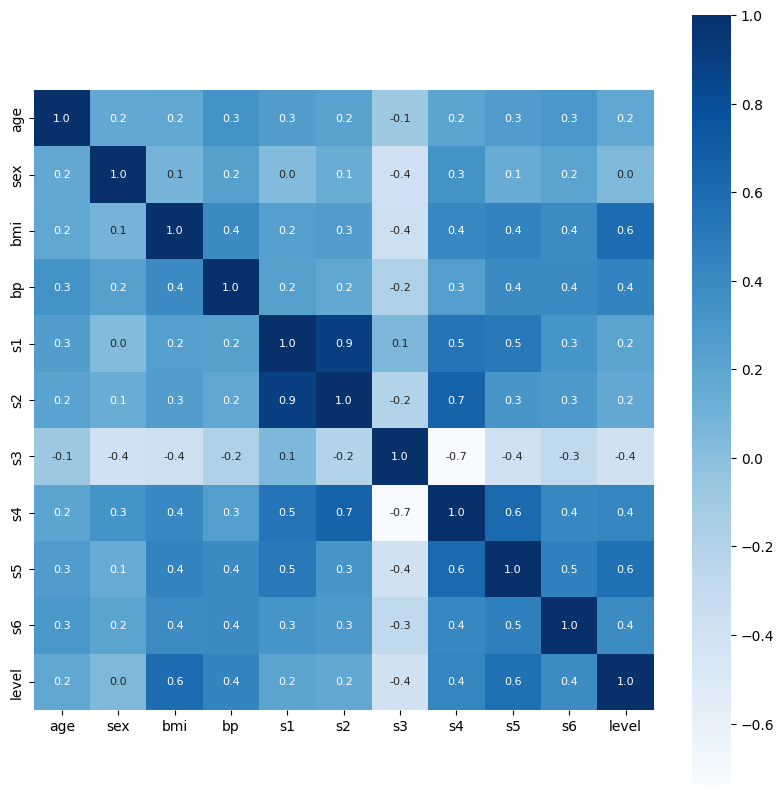

In [23]:
# constructing a heatmap to understand the correlation
plt.figure(figsize = (10,10))
sns.heatmap(correlation, cbar = True, square = True, fmt = '.1f', annot = True, annot_kws = {'size': 8}, cmap = 'Blues')

Splitting the data and Target

In [24]:
X = diabetes_prediction_dataframe.drop(['level'], axis = 1)
Y = diabetes_prediction_dataframe['level']

In [25]:
print(X)
print(Y)

          age       sex       bmi  ...        s4        s5        s6
0    0.038076  0.050680  0.061696  ... -0.002592  0.019907 -0.017646
1   -0.001882 -0.044642 -0.051474  ... -0.039493 -0.068332 -0.092204
2    0.085299  0.050680  0.044451  ... -0.002592  0.002861 -0.025930
3   -0.089063 -0.044642 -0.011595  ...  0.034309  0.022688 -0.009362
4    0.005383 -0.044642 -0.036385  ... -0.002592 -0.031988 -0.046641
..        ...       ...       ...  ...       ...       ...       ...
437  0.041708  0.050680  0.019662  ... -0.002592  0.031193  0.007207
438 -0.005515  0.050680 -0.015906  ...  0.034309 -0.018114  0.044485
439  0.041708  0.050680 -0.015906  ... -0.011080 -0.046883  0.015491
440 -0.045472 -0.044642  0.039062  ...  0.026560  0.044529 -0.025930
441 -0.045472 -0.044642 -0.073030  ... -0.039493 -0.004222  0.003064

[442 rows x 10 columns]
0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Name

Splitting the data into Training data and Test data

In [26]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 2)

In [27]:
print(X.shape, X_train.shape, X_test.shape)

(442, 10) (353, 10) (89, 10)


Model training

XGBoost Regressor model

In [28]:
# loading the model
model = XGBRegressor()

In [29]:
# training the model with X_train
model.fit(X_train, Y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

Evaluation

Preditcion on Training data

In [30]:
# accuracy for prediction on training data
training_data_prediction = model.predict(X_train)

In [31]:
print(training_data_prediction)

[ 48.079063 275.79562   47.075344 175.09784   60.05887   80.92295
 241.95184  196.78358  136.99768  128.96085  138.04382  159.3037
 116.05616  100.99508  146.95491   99.95836  143.94719   69.06398
 218.73909  107.06411  168.08066  235.98203  109.059    320.94815
 128.1941    43.169903  72.219925  55.010822 141.02443  282.91116
  58.938915 150.01672  345.89212  124.01583  186.04695  307.9844
 271.89774  189.9915    63.00553   91.10715   71.98547   65.05771
 157.91498   89.990265 185.04927   44.977837 198.95857  205.93909
  60.835712 139.13702  295.9103   280.9876   121.93976   94.97566
  40.080322 126.9906   144.95702  108.01841  185.0156    53.149784
 132.09827  101.08086  262.96768   94.052574 295.11963  258.63333
 232.12366  123.98313   76.96547  102.20505   95.910446  83.227005
 263.06934   71.079384 246.21504   66.19785  114.81357  221.9465
  92.91476  129.08292  128.22974  163.24394   99.01864   92.219925
 178.9825   140.08519   93.79107   97.014946 173.98544   61.036694
 202.0579

In [32]:
# R squared error
score_1 = metrics.r2_score(Y_train, training_data_prediction)

# Mean Absolute error
score_2 = metrics.mean_absolute_error(Y_train, training_data_prediction)

print("R squared error : ", score_1)
print("Mean Absolute Error : ", score_2)

R squared error :  0.9999964784927243
Mean Absolute Error :  0.09667098285793921


Visualizing the actual Level and predicted level

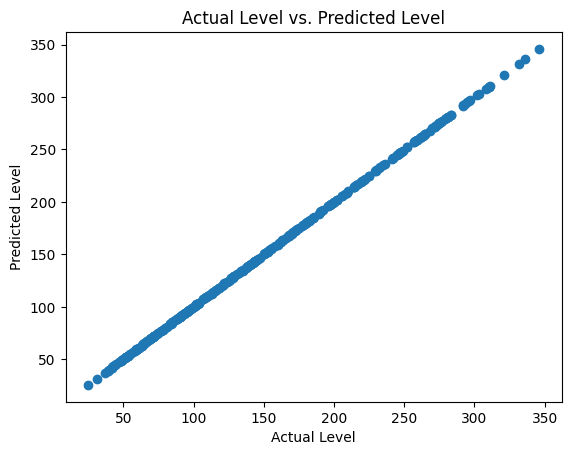

In [35]:
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Level")
plt.ylabel("Predicted Level")
plt.title("Actual Level vs. Predicted Level")
plt.show()

Prediction on Test Data

In [33]:
# accuracy for prediction on testing data
test_data_prediction = model.predict(X_test)

In [34]:
# R squared error
score_1 = metrics.r2_score(Y_test, test_data_prediction)

# Mean Absolute Error
score_2 = metrics.mean_absolute_error(Y_test, test_data_prediction)

print("R squared error : ", score_1)
print("Mean Absolute Error : ", score_2)

R squared error :  0.13255981697566832
Mean Absolute Error :  56.59495000089152
